# Lab05 · Making an MLP learn
### Sigmoid vs ReLU · Momentum · Adam · Dropout

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Tensor-Reloaded/Neural-Networks-2026/blob/main/Lab05/Lab05.ipynb)

**Neural Networks · 30 October 2026 · 2 hours.** Adapted from Cristian Simionescu's [Lab06/2025](https://github.com/Tensor-Reloaded/Neural-Networks-Template-2025/blob/8be443f/Lab06/Lab06.ipynb).

Why does a network fail to learn? We will separate three questions: **does a gradient reach the weights**, **how do we use it**, and **does the model generalize**?

| Minutes | Section | Your activity |
|---|---|---|
| 0–10 | Setup + recap | Identify forward, loss, backward and update |
| 10–35 | 1. Activations | Compare curves and local gradients; explain saturation |
| 35–65 | 2. Optimizers | Calculate two momentum steps; explore SGD and Adam trajectories |
| 65–80 | 3. Dropout mechanics | Predict a mask and distinguish train/eval behavior |
| 80–105 | 4. Train an MLP | Compare no dropout and two dropout rates on identical data |
| 105–120 | 5. Your experiment | Change one setting, record results and connect to Homework 3 |

**How to use:** in Colab, save a copy to Drive, then **Runtime → Run all**. CPU is enough; no GPU, external dataset downloads or API keys are needed. Colab already provides PyTorch, NumPy and Matplotlib. Locally, install `torch numpy matplotlib ipykernel` and select that Python kernel. Saved figures can be read directly on GitHub.

This is a runnable demonstration and experimentation notebook, not a replacement for the Homework 3 specification. PyTorch autograd computes derivatives here so we can focus on the mechanisms; follow the homework's own implementation restrictions.

In [1]:
import copy
import math
import platform
import time
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

SEED = 2026
torch.manual_seed(SEED)
np.random.seed(SEED)
torch.set_num_threads(2)
device = torch.device('cpu')  # Small demonstrations; CPU also makes classroom runs portable.
START = time.perf_counter()
COLORS = {'Sigmoid':'#0072B2', 'ReLU':'#D55E00', 'Leaky ReLU':'#807000',
          'SGD':'#0072B2', 'Momentum':'#D55E00', 'Adam':'#9C477B'}
STYLES = ['-', '--', '-.']
plt.rcParams.update({'figure.figsize': (11,4), 'figure.dpi': 110,
    'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.facecolor': 'white', 'figure.facecolor': 'white',
    'text.color': '#202632', 'axes.labelcolor': '#202632',
    'xtick.color': '#202632', 'ytick.color': '#202632', 'savefig.bbox': 'tight'})

def table(headers, rows):
    display(Markdown('| ' + ' | '.join(headers) + ' |\n| ' +
                     ' | '.join(['---']*len(headers)) + ' |\n' +
                     '\n'.join('| '+' | '.join(map(str,row))+' |' for row in rows)))

print(f'Python {platform.python_version()} · PyTorch {torch.__version__} · '
      f'NumPy {np.__version__} · device={device} · seed={SEED}')

Python 3.13.5 · PyTorch 2.14.1 · NumPy 2.2.6 · device=cpu · seed=2026


## 1 · Sigmoid vs ReLU: the derivative is the gate

For one hidden neuron, $z=w^Tx+b$, $a=f(z)$. Backpropagation multiplies the incoming gradient by $f'(z)$:

$$\frac{\partial L}{\partial z}=\frac{\partial L}{\partial a}\,f'(z).$$

- **Sigmoid:** $f(z)=1/(1+e^{-z})$, $f'(z)=f(z)(1-f(z))$. Large positive **or negative** inputs give very small derivatives. In exact arithmetic, the derivative is positive at every finite input; a computed zero can come from floating-point rounding.
- **ReLU:** $\max(0,z)$. Derivative 1 for $z>0$, 0 for $z<0$. It avoids positive-side saturation, but a unit inactive on all training examples receives no gradient through its activation (*dying ReLU*).
- **Leaky ReLU:** $z$ for $z>0$, $\alpha z$ otherwise. Here $\alpha=0.01>0$, so the negative branch still passes a small gradient.

These plots concern **hidden activations**. For binary output classification, sigmoid remains useful with BCE. With sigmoid+BCE, the combined logit derivative is $\sigma(z)-y$ per example, not an extra isolated sigmoid derivative. Prefer a stable logits-based loss in a library implementation. Multiclass classification usually uses softmax/cross-entropy, not ReLU probabilities.

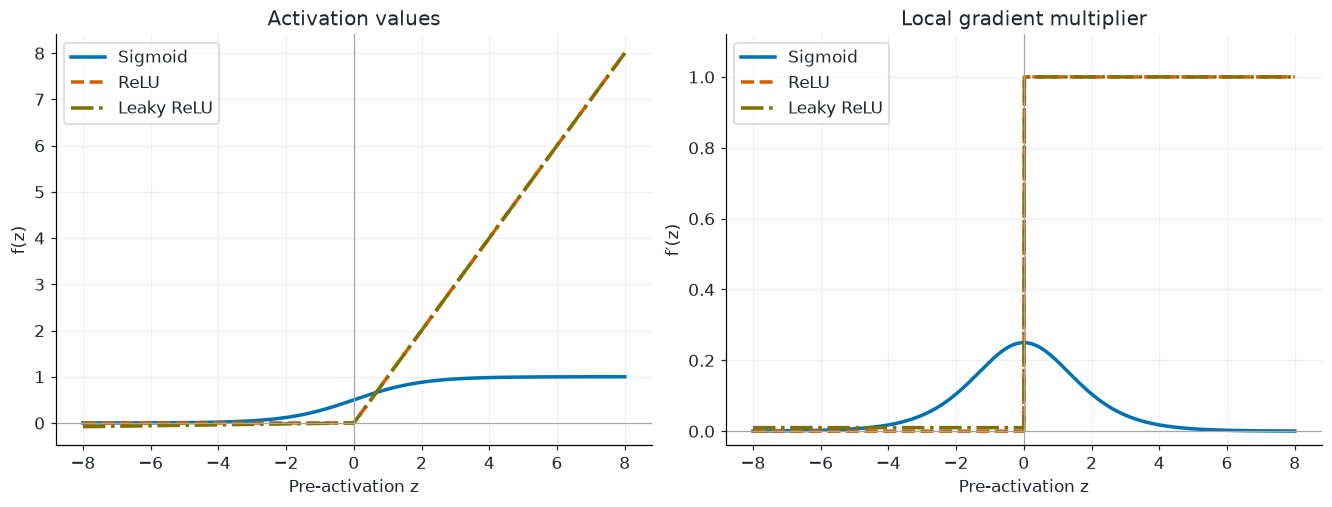

In [2]:
# Adapted from the activation/derivative demonstration in Lab06/2025.
def sigmoid(x):
    return torch.sigmoid(x)  # Stable implementation of the logistic function.

def relu(x):
    return torch.relu(x)

def leaky_relu(x, alpha=0.01):
    return torch.where(x > 0, x, alpha*x)

def elementwise_derivative(fn, xs):
    xs = xs.detach().clone().requires_grad_(True)
    return torch.autograd.grad(fn(xs).sum(), xs)[0]

activations = {'Sigmoid': sigmoid, 'ReLU': relu, 'Leaky ReLU': leaky_relu}
xs = torch.linspace(-8,8,1001,dtype=torch.float64)
fig, axes = plt.subplots(1,2,figsize=(12,4.5),layout='constrained')
for (name,fn),style in zip(activations.items(),STYLES):
    axes[0].plot(xs,fn(xs),label=name,color=COLORS[name],ls=style,lw=2.3)
    axes[1].plot(xs,elementwise_derivative(fn,xs),label=name,color=COLORS[name],ls=style,lw=2.3)
for ax in axes:
    ax.axvline(0,color='0.65',lw=.8); ax.axhline(0,color='0.65',lw=.8)
    ax.set_xlabel('Pre-activation z'); ax.grid(alpha=.2); ax.legend()
axes[0].set(title='Activation values',ylabel='f(z)')
axes[1].set(title='Local gradient multiplier',ylabel="f′(z)",ylim=(-.04,1.12))
plt.show()

### Predict before running

An incoming gradient has value **1**. How much reaches `z` when `z = -8, 0, 8`? What changes if it is **100** instead? At zero ReLU is not differentiable; the library chooses a convention (PyTorch uses 0).

In [3]:
probe = torch.tensor([-8.,0.,8.],dtype=torch.float64)
table(['Activation','z','f(z)',"f′(z)"],
      [[name,f'{z:g}',f'{a:.6f}',f'{d:.6f}']
       for name,fn in activations.items()
       for z,a,d in zip(probe,fn(probe),elementwise_derivative(fn,probe))])

| Activation | z | f(z) | f′(z) |
| --- | --- | --- | --- |
| Sigmoid | -8 | 0.000335 | 0.000335 |
| Sigmoid | 0 | 0.500000 | 0.250000 |
| Sigmoid | 8 | 0.999665 | 0.000335 |
| ReLU | -8 | 0.000000 | 0.000000 |
| ReLU | 0 | 0.000000 | 0.000000 |
| ReLU | 8 | 8.000000 | 1.000000 |
| Leaky ReLU | -8 | -0.080000 | 0.010000 |
| Leaky ReLU | 0 | 0.000000 | 0.010000 |
| Leaky ReLU | 8 | 8.000000 | 1.000000 |

### What happens across several layers?

We isolate the activation effect with a **scalar chain**: eight layers, each weight fixed to 1 and bias to 0, starting at $x=8$. The final activation is the scalar objective. The gradient reaching an earlier pre-activation passes through more local derivatives.

This is a controlled illustration, not a trained network. General networks also multiply by weight matrices; ReLU does not guarantee that all gradients stay well scaled.

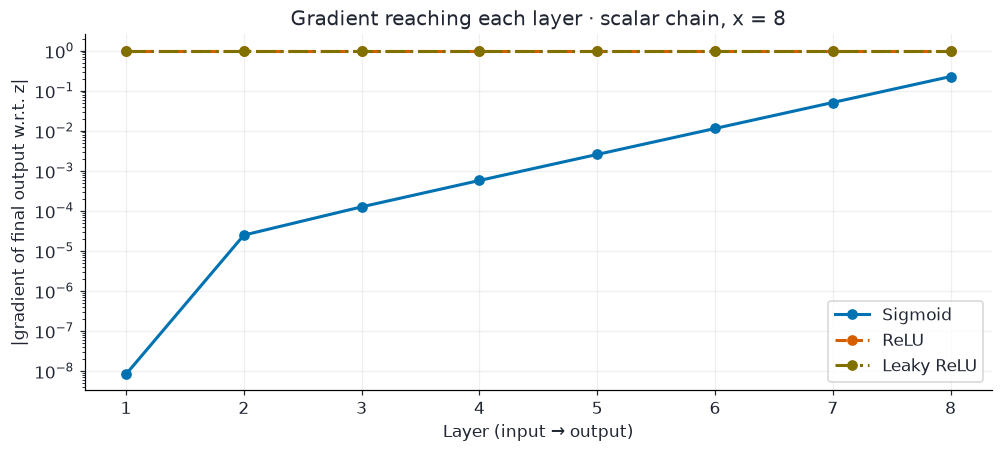

In [4]:
fig,ax = plt.subplots(figsize=(9,4),layout='constrained')
for (name,fn),style in zip(activations.items(),STYLES):
    a = torch.tensor(8.,dtype=torch.float64,requires_grad=True)
    zs=[]
    for _ in range(8):
        z = a*1.0
        zs.append(z); a=fn(z)
    grads = torch.autograd.grad(a,zs)
    ax.plot(range(1,9),[abs(g.item()) for g in grads],marker='o',ls=style,
            color=COLORS[name],label=name,lw=2)
ax.set(yscale='log',xticks=range(1,9),xlabel='Layer (input → output)',
       ylabel='|gradient of final output w.r.t. z|',title='Gradient reaching each layer · scalar chain, x = 8')
ax.legend(); ax.grid(alpha=.2); plt.show()

**Discuss:** why do ReLU and Leaky ReLU overlap here? Change the starting input to `-8` and reason about zero gradients before plotting them (zero cannot be shown on a logarithmic axis).

**Connection to initialization:** identical hidden weights preserve symmetry; random initialization lets units specialize. Very large weights can saturate sigmoid; very small weights can attenuate signals. Xavier is a common starting point for tanh; He is a common starting point for ReLU. Scaling inputs and choosing initialization are better first steps than blindly clipping activations.

## 2 · How optimizers use the gradient

Backpropagation **computes** gradients; the optimizer **updates** parameters.

| Method | Information carried between updates | Update idea |
|---|---|---|
| SGD | None | Follow the current negative gradient |
| Momentum | Velocity `v` | Accumulate a direction across steps |
| Adam | First moment `m`, second moment `v`, step `t` | Normalize a smoothed direction by a per-coordinate scale |

We use **unnormalized momentum** `v = beta*v + g`, then `w -= lr*v`, matching the Lab05 PDF. Last year's notebook used `(1-beta)*g`; the numerical learning rates are not directly interchangeable between these conventions.

Adam uses `m = beta1*m + (1-beta1)*g`, `v = beta2*v + (1-beta2)*g²`, then bias-corrects both moments. Its second moment is not a centered variance. No optimizer wins on every objective or with every learning rate.

In [5]:
def sgd_step(w, g, state, lr=0.05):
    return w - lr * g, state

def momentum_step(w, g, state, lr=0.05, beta=0.9):
    velocity = beta*state.get('velocity', torch.zeros_like(w)) + g
    state['velocity'] = velocity
    return w - lr*velocity, state

def adam_step(w, g, state, lr=0.05, b1=0.9, b2=0.999, eps=1e-8):
    m = state.get('m', torch.zeros_like(w))
    v = state.get('v', torch.zeros_like(w))
    t = state.get('t', 0) + 1
    m = b1 * m + (1 - b1) * g
    v = b2 * v + (1 - b2) * (g * g)
    m_hat = m / (1 - b1**t)
    v_hat = v / (1 - b2**t)
    w = w - lr * m_hat / (torch.sqrt(v_hat) + eps)
    state['m'], state['v'], state['t'] = m, v, t
    return w, state

optimizers = {'SGD':sgd_step, 'Momentum':momentum_step, 'Adam':adam_step}

### Pencil-and-paper exercise · 5 minutes

Start with `w=1`, velocity `v=0`, `lr=0.1`, `beta=0.9`. The next gradients are `g₁=2`, then `g₂=-1`.

Compute the two new weights with SGD and with momentum. Explain why momentum can keep moving in the previous direction after the gradient changes sign. Then try `beta=0`.

### 2.1 · Watch the steps on a parabola

Adapted from last year's 1D optimizer comparison. All methods start at the same point and get the same 40-update budget. Equal numerical learning rates do not imply equal update magnitudes across algorithms. Edit the learning rates and rerun this cell.

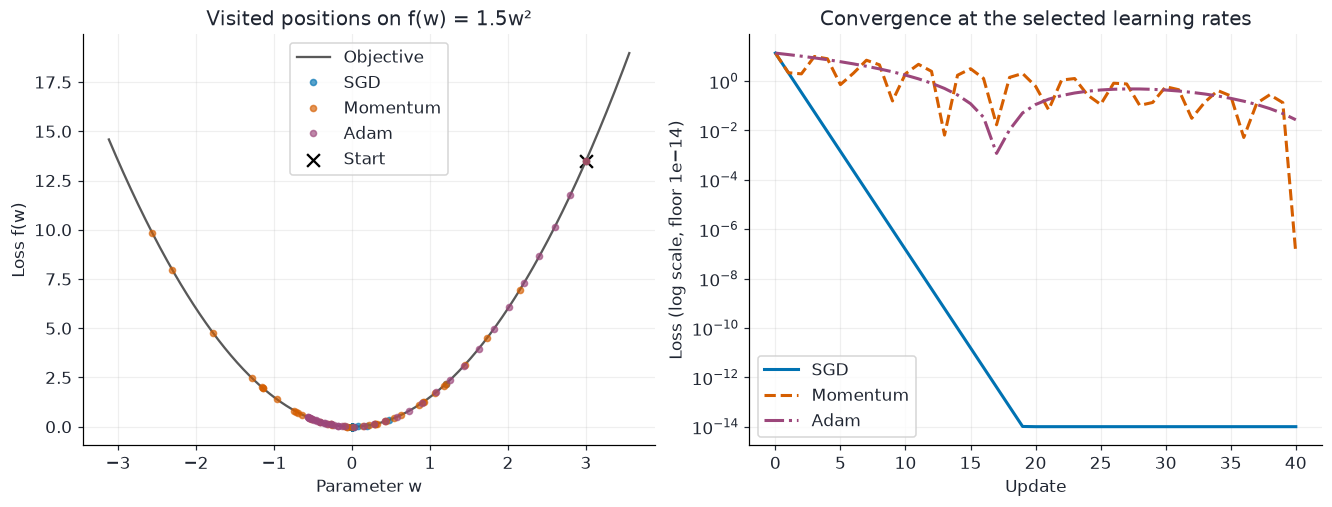

| Method | Learning rate | Final w | Final loss |
| --- | --- | --- | --- |
| SGD | 0.2 | 0.00000 | 1.973e-31 |
| Momentum | 0.2 | 0.00026 | 1.029e-07 |
| Adam | 0.2 | -0.13408 | 0.02697 |

In [6]:
#@title 1D optimizer experiment
STEPS = 40 #@param {type:'integer'}
SGD_LR = 0.2 #@param {type:'number'}
MOMENTUM_LR = 0.2 #@param {type:'number'}
ADAM_LR = 0.2 #@param {type:'number'}
lrs = {'SGD':SGD_LR, 'Momentum':MOMENTUM_LR, 'Adam':ADAM_LR}

def quadratic(w): return 1.5*w*w
def quadratic_grad(w): return 3*w

def trajectory(f,grad,start,step_fn,lr,steps):
    w = start.clone(); state={}; path=[w.numpy().copy()]; values=[float(f(w))]
    for _ in range(steps):
        w,state = step_fn(w,grad(w),state,lr=lr)
        path.append(w.numpy().copy()); values.append(float(f(w)))
    return np.asarray(path),np.asarray(values)

trajectories={name:trajectory(quadratic,quadratic_grad,torch.tensor(3.,dtype=torch.float64),fn,lrs[name],STEPS)
              for name,fn in optimizers.items()}
fig,axes=plt.subplots(1,2,figsize=(12,4.5),layout='constrained')
positions=np.concatenate([path.ravel() for path,_ in trajectories.values()])
finite=positions[np.isfinite(positions)]
span=max(1.,float(finite.max()-finite.min()))
grid=np.linspace(finite.min()-.1*span,finite.max()+.1*span,500)
axes[0].plot(grid,1.5*grid**2,color='0.35',lw=1.5,label='Objective')
for (name,(path,values)),style in zip(trajectories.items(),STYLES):
    axes[0].plot(path,values,'o',ms=4,alpha=.65,color=COLORS[name],label=name)
    axes[1].plot(range(STEPS+1),np.maximum(values,1e-14),ls=style,color=COLORS[name],lw=2,label=name)
axes[0].scatter([3],[13.5],color='black',marker='x',s=70,label='Start')
axes[0].set(xlabel='Parameter w',ylabel='Loss f(w)',title='Visited positions on f(w) = 1.5w²')
axes[1].set(xlabel='Update',ylabel='Loss (log scale, floor 1e−14)',yscale='log',title='Convergence at the selected learning rates')
for ax in axes: ax.grid(alpha=.2); ax.legend()
plt.show()
table(['Method','Learning rate','Final w','Final loss'],
      [[n,lrs[n],f'{p[-1]:.5f}',f'{v[-1]:.4g}'] for n,(p,v) in trajectories.items()])

**Try:** set SGD's learning rate to `0.01`, then `0.65`, then `0.7`. Explain slow learning, oscillation and divergence. For this parabola, the stable range is `0 < lr < 2/3`. At `2/3`, the error flips sign without shrinking.

### 2.2 · A curved valley: Rosenbrock

This retains last year's second optimizer example. The optimum is `(1,1)`. Each optimizer has an explicit learning rate and the same 400-update budget; these settings are illustrative, not an exhaustive tuning comparison. The plot is evidence about **this run**, not proof that Adam or momentum is universally faster.

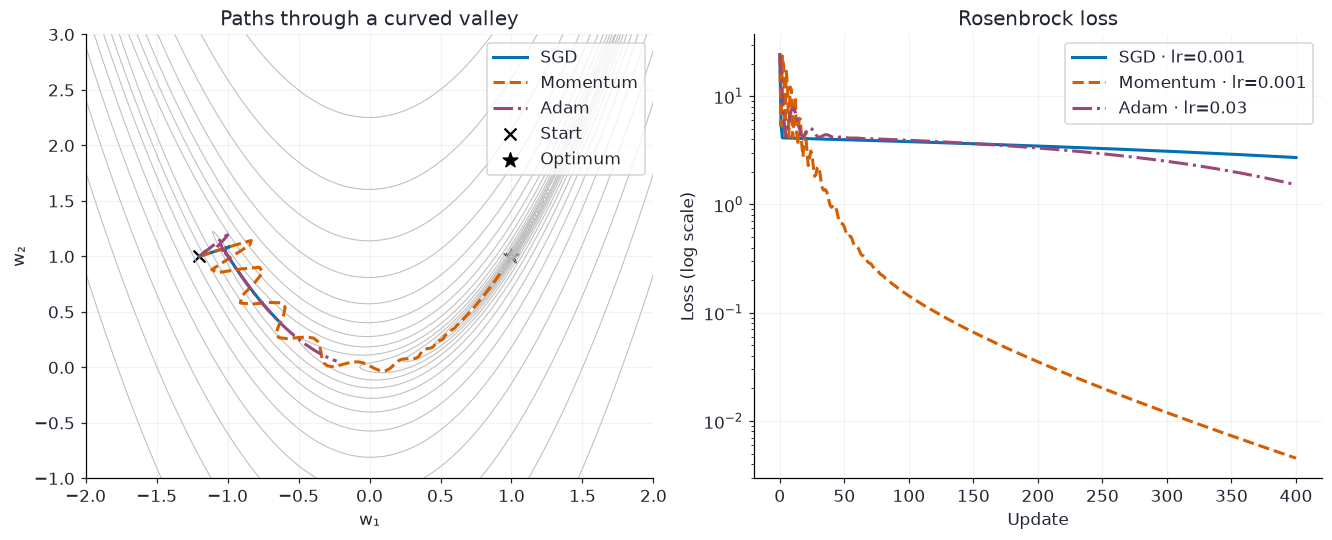

| Method | Learning rate | Final loss |
| --- | --- | --- |
| SGD | 0.001 | 2.711 |
| Momentum | 0.001 | 0.004533 |
| Adam | 0.03 | 1.519 |

In [7]:
def make_rosenbrock(a=1.0, b=100.0):
    def f2(w):
        x, y = w[0], w[1]
        return (a - x)**2 + b * (y - x**2)**2
    def g2(w):
        x, y = w[0], w[1]
        dx = -2*(a - x) - 4*b*x*(y - x**2)
        dy =  2*b*(y - x**2)
        return torch.stack([dx, dy])
    return f2, g2

f2,g2=make_rosenbrock()
VALLEY_STEPS=400
valley_lrs={'SGD':1e-3,'Momentum':1e-3,'Adam':3e-2}
valley={name:trajectory(f2,g2,torch.tensor([-1.2,1.],dtype=torch.float64),fn,valley_lrs[name],VALLEY_STEPS)
        for name,fn in optimizers.items()}
fig,axes=plt.subplots(1,2,figsize=(12,4.8),layout='constrained')
x,y=np.meshgrid(np.linspace(-2,2,300),np.linspace(-1,3,300))
axes[0].contour(x,y,(1-x)**2+100*(y-x*x)**2,levels=np.logspace(-2,3,18),colors='0.75',linewidths=.7)
for (name,(path,values)),style in zip(valley.items(),STYLES):
    axes[0].plot(path[:,0],path[:,1],ls=style,color=COLORS[name],lw=2,label=name)
    axes[1].plot(values,ls=style,color=COLORS[name],lw=2,label=f'{name} · lr={valley_lrs[name]}')
axes[0].scatter([-1.2],[1],c='black',marker='x',s=60,label='Start')
axes[0].scatter([1],[1],c='black',marker='*',s=100,label='Optimum')
axes[0].set(xlabel='w₁',ylabel='w₂',title='Paths through a curved valley',xlim=(-2,2),ylim=(-1,3))
axes[1].set(xlabel='Update',ylabel='Loss (log scale)',yscale='log',title='Rosenbrock loss')
for ax in axes: ax.legend(); ax.grid(alpha=.15)
plt.show()
table(['Method','Learning rate','Final loss'],[[n,valley_lrs[n],f'{v[-1]:.4g}'] for n,(p,v) in valley.items()])

## 3 · Dropout: temporarily remove activations, not weights

For each training forward pass, draw a Bernoulli mask with keep probability $1-p$:

$$\widetilde a = \frac{m\odot a}{1-p},\qquad m_i\sim\mathrm{Bernoulli}(1-p).$$

This is **inverted dropout**: retained activations are scaled during training, so $E[\widetilde a_i\mid a_i]=a_i$. At evaluation we use the original activations, with no mask and no extra scaling. The deterministic evaluation network is an approximation, not the exact average of all nonlinear subnetworks.

Dropout adds noise during learning and discourages reliance on one hidden activation. It is applied to hidden activations here, not input labels or the regression output. It does not permanently delete neurons and does not guarantee better validation performance.

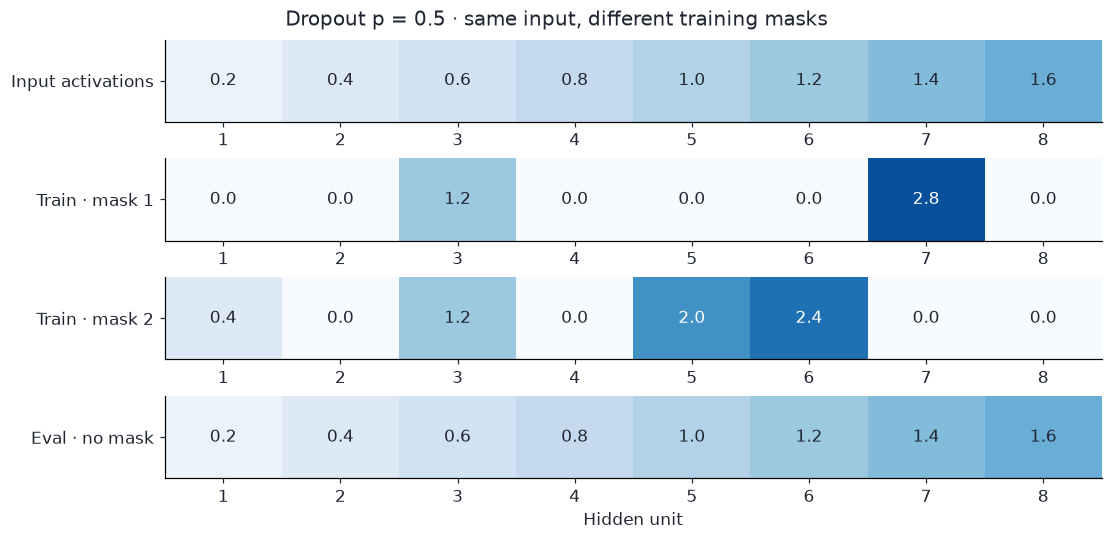

In [8]:
# Adapted from MyDropout in Lab06/2025.
class MyDropout(nn.Module):
    def __init__(self,p=0.3):
        super().__init__()
        if not 0 <= p < 1:
            raise ValueError('Dropout probability must satisfy 0 <= p < 1.')
        self.p=p
    def forward(self,x):
        if not self.training or self.p==0:
            return x
        mask=(torch.rand_like(x)>=self.p).to(x.dtype)
        return mask*x/(1-self.p)

torch.manual_seed(SEED)
example=torch.tensor([[.2,.4,.6,.8,1.,1.2,1.4,1.6]])
drop=MyDropout(.5)
drop.train(); pass1=drop(example); pass2=drop(example)
drop.eval(); eval_pass=drop(example)
fig,axes=plt.subplots(4,1,figsize=(10,4.8),layout='constrained')
for ax,values,label in zip(axes,[example,pass1,pass2,eval_pass],
                            ['Input activations','Train · mask 1','Train · mask 2','Eval · no mask']):
    ax.imshow(values.numpy(),cmap='Blues',vmin=0,vmax=3.2,aspect='auto')
    for j,value in enumerate(values[0]):
        ax.text(j,0,f'{value:.1f}',ha='center',va='center',color='white' if value>1.8 else '#202632')
    ax.set(yticks=[0],yticklabels=[label],xticks=range(8),xticklabels=range(1,9))
axes[-1].set_xlabel('Hidden unit'); fig.suptitle('Dropout p = 0.5 · same input, different training masks')
plt.show()

**Predict:** what happens at `p=0`? Why are surviving values doubled at `p=0.5`? What goes wrong if dropout remains active when reporting validation loss?

## 4 · Train an MLP: fitting data vs generalizing

We keep last year's synthetic regression problem, **sin(2x) + noise**, and manual linear/dropout/optimizer implementation. A deliberately small noisy training set (20 points) makes the trade-off easier to see. Hidden biases start uniformly in [-0.5, 0.5] to spread the initial ReLU breakpoints across the 1D input; the same initial biases and weights are reused for every dropout rate.

Three networks have **identical initial weights**, data, width, activation, update budget and Adam settings. Only dropout probability changes: `0`, `0.2`, `0.5`. We use the same random seed before each run. Both reported train and validation MSE are measured in **eval mode after each update**, so dropout noise is not accidentally included in only one curve.

This is a controlled single-seed teaching experiment: no test set is used and these validation results are not an unbiased final performance estimate. The smooth target curve is known only because we generated the data; it is drawn for explanation, never used as a training target.

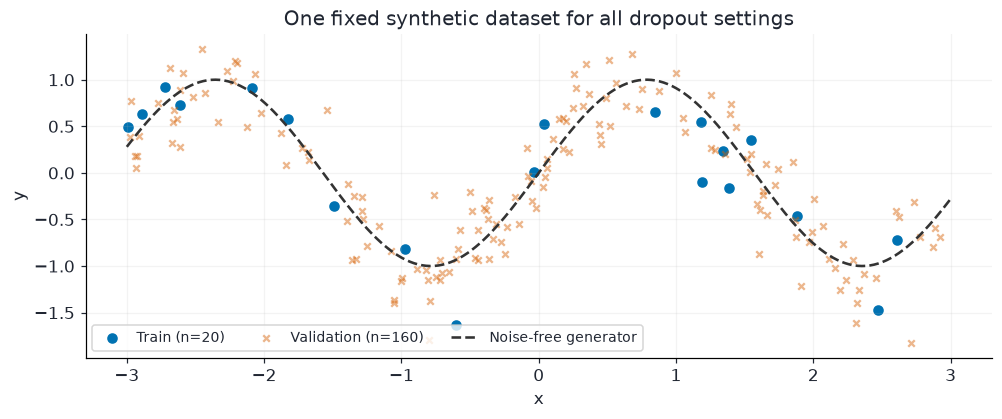

In [9]:
#@title Regression experiment — edit here, then rerun section 4
N_TRAIN = 20 #@param {type:'integer'}
N_VALIDATION = 160 #@param {type:'integer'}
NOISE = 0.3 #@param {type:'number'}
WIDTH = 64 #@param {type:'integer'}
EPOCHS = 1600 #@param {type:'integer'}
TRAIN_LR = 0.003 #@param {type:'number'}
ACTIVATION = 'relu' #@param ['relu', 'sigmoid', 'leaky_relu']
DROPOUT_RATES = [0.0,0.2,0.5]

generator=torch.Generator().manual_seed(SEED)
x_all=6*torch.rand(N_TRAIN+N_VALIDATION,1,generator=generator)-3
y_all=torch.sin(2*x_all)+NOISE*torch.randn(x_all.shape,generator=generator)
xtr,ytr=x_all[:N_TRAIN],y_all[:N_TRAIN]
xva,yva=x_all[N_TRAIN:],y_all[N_TRAIN:]
x_plot=torch.linspace(-3,3,400).unsqueeze(1)
fig,ax=plt.subplots(figsize=(9,3.7),layout='constrained')
ax.scatter(xtr,ytr,s=35,marker='o',color='#0072B2',label=f'Train (n={N_TRAIN})')
ax.scatter(xva,yva,s=18,marker='x',alpha=.45,color='#D55E00',label=f'Validation (n={N_VALIDATION})')
ax.plot(x_plot,torch.sin(2*x_plot),color='0.2',ls='--',lw=1.7,label='Noise-free generator')
ax.set(xlabel='x',ylabel='y',title='One fixed synthetic dataset for all dropout settings')
ax.legend(ncol=3,fontsize=9); ax.grid(alpha=.15); plt.show()

In [10]:
# Reduced from the 2025 model: no BatchNorm/LayerNorm in today's experiment.
class MyLinear(nn.Module):
    def __init__(self,in_features,out_features,hidden=False,activation='relu'):
        super().__init__()
        scale=math.sqrt(2/in_features) if hidden and activation in ('relu','leaky_relu') else math.sqrt(2/(in_features+out_features))
        self.W=nn.Parameter(torch.randn(in_features,out_features)*scale)
        self.b=nn.Parameter(torch.zeros(out_features))
    def forward(self,x):
        return x@self.W+self.b

class MLP(nn.Module):
    def __init__(self,width=64,activation='relu',dropout_p=0.):
        super().__init__()
        self.layers=nn.ModuleList([MyLinear(1,width,True,activation),
                                  MyLinear(width,width,True,activation),MyLinear(width,1)])
        self.dropout=MyDropout(dropout_p)
        self.act={'relu':relu,'sigmoid':sigmoid,'leaky_relu':leaky_relu}[activation]
    def forward(self,x):
        for layer in self.layers[:-1]:
            x=self.dropout(self.act(layer(x)))
        return self.layers[-1](x)  # Linear output: regression values can be negative.

@torch.no_grad()
def update_parameters(model,states,lr):
    for parameter,state in zip(model.parameters(),states):
        updated,_=adam_step(parameter,parameter.grad,state,lr=lr)
        parameter.copy_(updated)

def train_regression(model,epochs,lr):
    states=[{} for _ in model.parameters()]
    history={'train':[],'validation':[]}
    best_loss=float('inf'); best_state=None; best_epoch=None
    for epoch in range(epochs):
        model.train()
        model.zero_grad(set_to_none=True)
        prediction=model(xtr)
        loss=((prediction-ytr)**2).mean()
        loss.backward()
        update_parameters(model,states,lr)
        model.eval()
        with torch.no_grad():
            train_loss=((model(xtr)-ytr)**2).mean().item()
            val_loss=((model(xva)-yva)**2).mean().item()
        history['train'].append(train_loss); history['validation'].append(val_loss)
        if val_loss < best_loss:
            best_loss=val_loss; best_state=copy.deepcopy(model.state_dict()); best_epoch=epoch+1
    # Keep final weights for a fair fixed-budget plot; archive the best epoch separately.
    return history,{'state':best_state,'epoch':best_epoch,'validation_mse':best_loss}

In [11]:
torch.manual_seed(SEED)
initial_model=MLP(WIDTH,ACTIVATION)
# Spread the initial ReLU breakpoints across this 1D toy input. Shared by all runs.
with torch.no_grad():
    for layer in initial_model.layers[:-1]:
        layer.b.uniform_(-0.5,0.5)
initial_state=copy.deepcopy(initial_model.state_dict())
models={}; histories={}; best_checkpoints={}
training_start=time.perf_counter()
for rate in DROPOUT_RATES:
    model=MLP(WIDTH,ACTIVATION,rate)
    model.load_state_dict(initial_state)
    torch.manual_seed(SEED+1)
    hist,best=train_regression(model,EPOCHS,TRAIN_LR)
    models[rate]=model; histories[rate]=hist; best_checkpoints[rate]=best
print(f'Trained {len(models)} models, {EPOCHS} full-batch updates each, in {time.perf_counter()-training_start:.1f}s on CPU.')
table(['Dropout p','Final train MSE','Final validation MSE','Best validation epoch','Best validation MSE'],
      [[p,f"{histories[p]['train'][-1]:.4f}",f"{histories[p]['validation'][-1]:.4f}",
        best_checkpoints[p]['epoch'],f"{best_checkpoints[p]['validation_mse']:.4f}"] for p in DROPOUT_RATES])

Trained 3 models, 1600 full-batch updates each, in 2.1s on CPU.


| Dropout p | Final train MSE | Final validation MSE | Best validation epoch | Best validation MSE |
| --- | --- | --- | --- | --- |
| 0.0 | 0.0500 | 0.2536 | 80 | 0.1974 |
| 0.2 | 0.0752 | 0.1977 | 389 | 0.1911 |
| 0.5 | 0.2171 | 0.2814 | 1577 | 0.2621 |

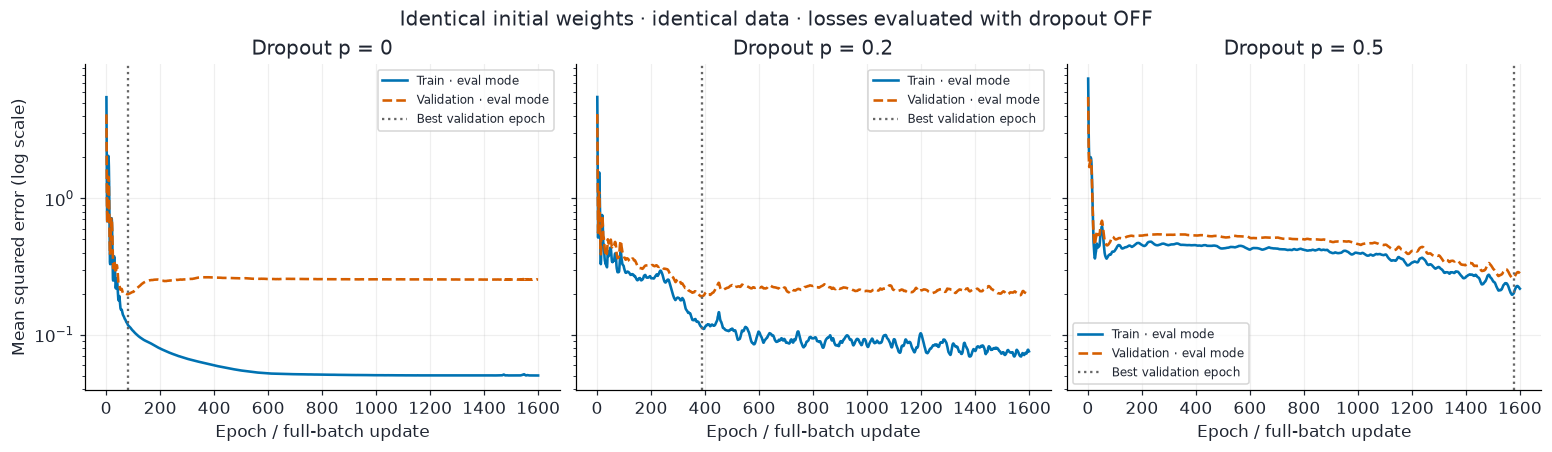

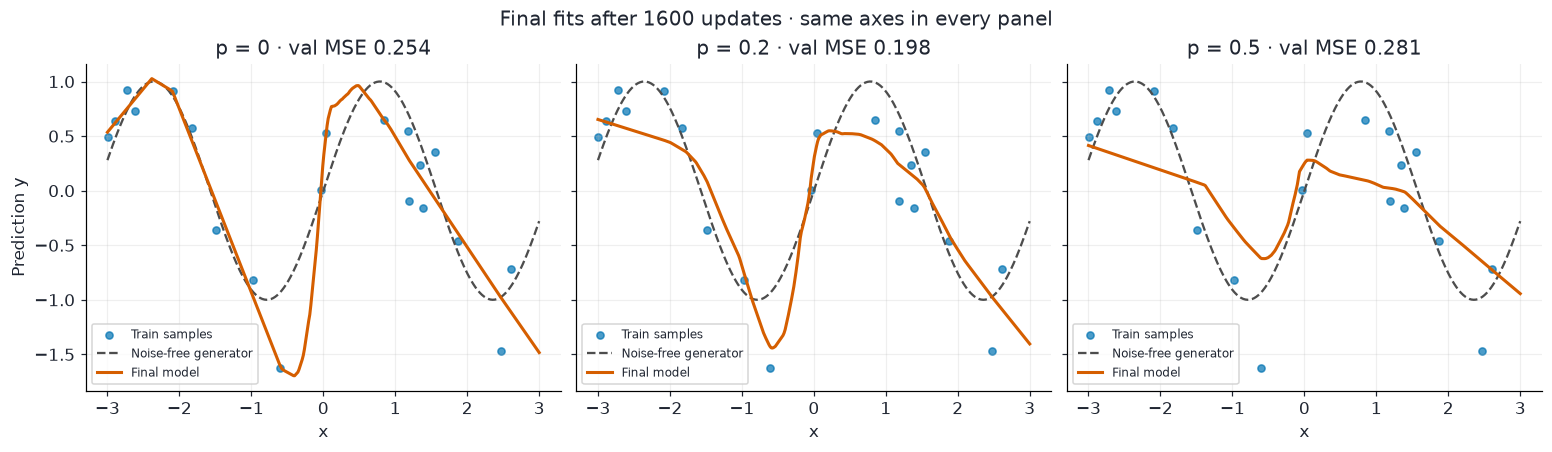

In [12]:
fig,axes=plt.subplots(1,3,figsize=(14,4),layout='constrained',sharey=True)
for ax,rate in zip(axes,DROPOUT_RATES):
    hist=histories[rate]; epochs=np.arange(1,EPOCHS+1)
    ax.plot(epochs,hist['train'],color='#0072B2',lw=1.7,label='Train · eval mode')
    ax.plot(epochs,hist['validation'],color='#D55E00',ls='--',lw=1.7,label='Validation · eval mode')
    ax.axvline(best_checkpoints[rate]['epoch'],color='0.4',ls=':',label='Best validation epoch')
    ax.set(title=f'Dropout p = {rate:g}',xlabel='Epoch / full-batch update',yscale='log')
    ax.grid(alpha=.2); ax.legend(fontsize=8)
axes[0].set_ylabel('Mean squared error (log scale)')
fig.suptitle('Identical initial weights · identical data · losses evaluated with dropout OFF')
plt.show()

fig,axes=plt.subplots(1,3,figsize=(14,4),layout='constrained',sharex=True,sharey=True)
for ax,rate in zip(axes,DROPOUT_RATES):
    model=models[rate]; model.eval()
    with torch.no_grad(): predicted=model(x_plot)
    ax.scatter(xtr,ytr,color='#0072B2',s=22,alpha=.7,label='Train samples')
    ax.plot(x_plot,torch.sin(2*x_plot),color='0.3',ls='--',label='Noise-free generator')
    ax.plot(x_plot,predicted,color='#D55E00',lw=2,label='Final model')
    ax.set(title=f'p = {rate:g} · val MSE {histories[rate]["validation"][-1]:.3f}',xlabel='x')
    ax.grid(alpha=.2); ax.legend(fontsize=8)
axes[0].set_ylabel('Prediction y')
fig.suptitle(f'Final fits after {EPOCHS} updates · same axes in every panel')
plt.show()

**Read the result, not the label:** a lower training loss does not automatically mean better generalization. Which rate has the lowest **validation** MSE in this run? Does stronger dropout underfit? Does the best validation epoch differ from the last epoch?

The final-fit plots use the **last** weights, not the selected best checkpoint. In a real workflow, choose settings and stopping time using validation, then evaluate the chosen model once on a held-out test set. Do not select an epoch using test performance.

### Does evaluation really switch dropout off?

A final demonstration: the same trained model sees the same inputs twice in train mode, then twice in eval mode. Training predictions differ because masks change; eval predictions should overlap. `eval()` changes layer behavior; it does **not** disable autograd by itself.

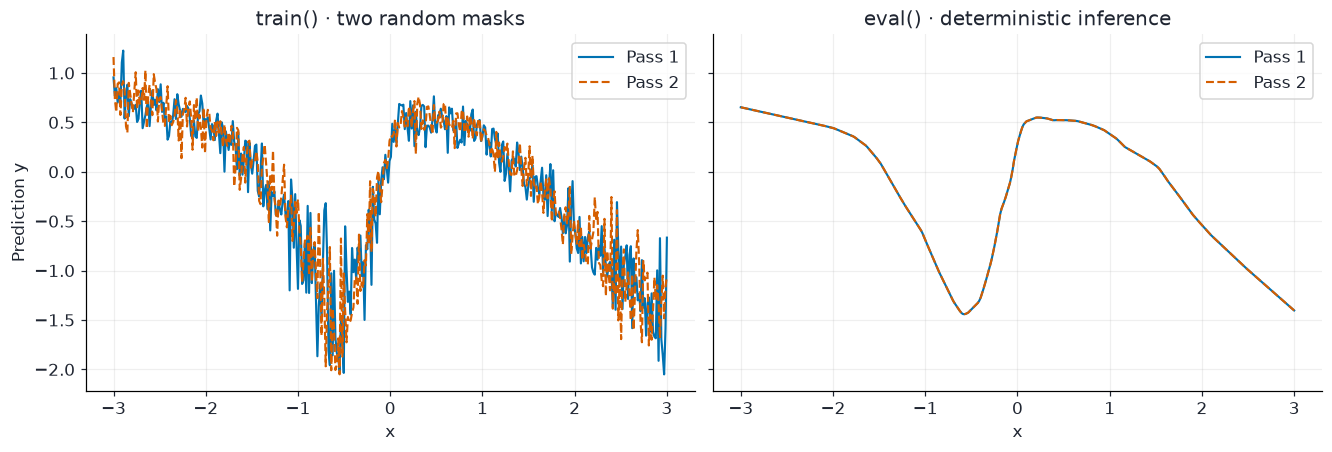

Largest difference between two eval passes: 0.000000


In [13]:
model=models[0.2]
torch.manual_seed(SEED+2)
with torch.no_grad():
    model.train(); train1=model(x_plot); train2=model(x_plot)
    model.eval(); eval1=model(x_plot); eval2=model(x_plot)
fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained',sharey=True)
for ax,a,b,title in zip(axes,[train1,eval1],[train2,eval2],['train() · two random masks','eval() · deterministic inference']):
    ax.plot(x_plot,a,color='#0072B2',lw=1.4,label='Pass 1')
    ax.plot(x_plot,b,color='#D55E00',ls='--',lw=1.4,label='Pass 2')
    ax.set(title=title,xlabel='x'); ax.legend(); ax.grid(alpha=.2)
axes[0].set_ylabel('Prediction y'); plt.show()
print(f'Largest difference between two eval passes: {(eval1-eval2).abs().max().item():.6f}')

## 5 · Your experiment · 15 minutes

Choose **one** experiment, make a prediction, then change only the specified setting. Record a small before/after table with your settings, training MSE, validation MSE and observation. No automatic answer checks are supplied.

1. **Activation:** run section 4 with sigmoid, then ReLU. The initialization policy also adapts to the activation in `MyLinear`; record that this compares practical configurations, not an isolated activation effect. For a stricter comparison, keep the same initialization in both runs.
2. **Learning rate:** change the three learning rates in the 1D cell. Find settings that oscillate and settings that settle. Explain why comparing optimizers at one equal numerical learning rate is insufficient.
3. **Data vs dropout:** change `N_TRAIN` from 20 to 160, keeping `N_VALIDATION` fixed. Regenerating the dataset changes the split, so compare dropout rates **within each run**, not as a perfectly paired cross-run ablation.
4. **Regularization strength:** replace `0.5` with `0.7` in `DROPOUT_RATES`, then rerun section 4. Identify evidence of underfitting or overfitting rather than assuming more dropout is better. Keep `0.2` in the list for the train/eval demonstration.

**Bring this back to Homework 3:** identify your hidden activation and output/loss pairing; inspect loss and gradient scales; use a reproducible split; separate gradient computation from parameter updates; reset optimizer state between independent runs; disable dropout for evaluation; select settings on validation. The homework's required implementation rules still apply.

### References and provenance

- Adapted examples: [Cristian's Lab06/2025](https://github.com/Tensor-Reloaded/Neural-Networks-Template-2025/blob/8be443f/Lab06/Lab06.ipynb): activation derivatives, 1D/Rosenbrock optimizer trajectories, manual Adam, synthetic sine regression and inverted dropout. This edition reduces the scope, aligns momentum with the Lab05 PDF and controls initialization across dropout runs.
- [Current Lab05 resources and Homework 3](https://github.com/Tensor-Reloaded/Neural-Networks-2026/tree/main/Lab05)
- [Course 5: activations, initialization and regularization](https://drive.google.com/file/d/1Miafi_98lceBEcO5rIGS1xKxyrBT2AGZ/view)
- [Adam: A Method for Stochastic Optimization](https://arxiv.org/abs/1412.6980)
- [Dropout: A Simple Way to Prevent Neural Networks from Overfitting](https://jmlr.org/papers/v15/srivastava14a.html)
- [PyTorch Dropout](https://docs.pytorch.org/docs/stable/generated/torch.nn.Dropout.html) · [BCEWithLogitsLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html)

All datasets in this notebook are synthetic. This lab demonstrates mechanisms; it does not establish an optimizer or regularizer ranking across tasks. No GPU is required.

In [14]:
print(f'Notebook completed in {time.perf_counter()-START:.1f}s on {device}.')

Notebook completed in 3.8s on cpu.
